<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Population statements need dates and statement keys

**How can we inspect population claims while keeping their dates and references
attached to the right observation?** We will retrieve three Wikidata entities,
inspect their population statements, aggregate qualifiers and references at the
statement level, and compare that result with a join that multiplies rows.

The default uses an unchanged **recorded public Wikidata API response**, served
locally through the real worker. It is structured CC0 data, not invented cities or
population values. The three items are not harmonized statistical geographies:
this notebook describes their statements, not a ranking of city sizes or a current
population estimate. No Wikipedia article text is reproduced.

## Choose the displayed years and data source

`MIN_YEAR` is an inclusive lower bound on the point-in-time qualifier's year,
from 1800 through 2025. The experiment moves 2000 to 2010. It affects the population
plot; the full-source join audit stays fixed. Dates are shown at year resolution,
while the original time string and precision remain available in SQL.

`DATA_MODE='recorded'` uses the bundled snapshot. Set it to `'live'` for five bounded,
public Wikidata reads; labels and timestamps will identify that run. There is no
fallback to recorded data. Separate live responses can change; revision checks fail
if they cannot be joined consistently. Restart the kernel and run all after editing.

In [1]:
MIN_YEAR = 2000
DATA_MODE = "recorded"

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import json
from pathlib import Path
from datetime import datetime, timezone
from tempfile import TemporaryDirectory
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from replay import Replay
from notebook_support import theme, finish, prose

if type(MIN_YEAR) is not int or not 1800 <= MIN_YEAR <= 2025:
    raise ValueError("MIN_YEAR must be an integer from 1800 through 2025.")
if DATA_MODE not in ("recorded", "live"):
    raise ValueError("DATA_MODE must be recorded or live.")
manifest = json.loads(Path("fixtures/manifest.json").read_text())
run_started = datetime.now(timezone.utc).isoformat()
replay = Replay() if DATA_MODE == "recorded" else None
api_url = replay.url if replay else manifest["source_api"]
provenance = (
    f"Recorded public Wikidata · Captured {manifest['retrieved_at_utc'][:19]} UTC"
    if replay
    else f"Live public Wikidata · Run began {run_started[:19]} UTC"
)
source_line = "Wikidata CC0 · P1082 population statements · " + (
    "Recorded response" if replay else "Live responses"
)
points = join_audit = checks = pd.DataFrame()
secret_directory = TemporaryDirectory(prefix="vgi-wikipedia-secrets-")
con = haybarn.connect(
    config={"secret_directory": secret_directory.name, "allow_persistent_secrets": False}
)
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline
prose(provenance)

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-wikipedia/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-wikipedia/notebooks/pyproject.toml.

Recorded public Wikidata · Captured 2026-11-14T10:39:37 UTC

## Attach the pinned worker and retrieve bounded snapshots

The literal Git-backed `uvx` command needs no local worker checkout. All five
calls use the same three item IDs and public API contract. `cache_seconds=0`
makes the five retrievals explicit; the recorded fixture answers each exact request
with the same original bytes. Each result is materialized once before display.

The full statement table preserves all ranks. The separate `rank='best'` call
selects preferred statements if present, otherwise normal statements, per property.
That is Wikidata rank selection, not a fresh measurement or a “latest date” function.
`source_api`, entity revision, requested ID and statement ID together identify the
context we will join. The replay endpoint is local; canonical provenance is linked
in the table below and in the manifest.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'wiki' (TYPE vgi,LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with rdflib==7.6.0 --from git+https://github.com/Query-farm/vgi-wikipedia@a0f139f7f6d7ce7a1f1a01e3ad48ab45a4cb8811 vgi-wikipedia-worker');
CREATE TABLE entities AS SELECT * FROM wiki.wikidata.entity(['Q60','Q84','Q90'],api_url:='{{ api_url }}',cache_seconds:=0);
CREATE TABLE statements AS SELECT * FROM wiki.wikidata.statements(['Q60','Q84','Q90'],property_id:='P1082',rank:='all',api_url:='{{ api_url }}',cache_seconds:=0);
CREATE TABLE qualifiers AS SELECT * FROM wiki.wikidata.qualifiers(['Q60','Q84','Q90'],property_id:='P1082',rank:='all',api_url:='{{ api_url }}',cache_seconds:=0);
CREATE TABLE reference_snaks AS SELECT * FROM wiki.wikidata.statement_references(['Q60','Q84','Q90'],property_id:='P1082',rank:='all',api_url:='{{ api_url }}',cache_seconds:=0);
CREATE TABLE best AS SELECT * FROM wiki.wikidata.statements(['Q60','Q84','Q90'],property_id:='P1082',rank:='best',api_url:='{{ api_url }}',cache_seconds:=0);
SELECT entity_id,label,label_language,entity_revision,modified,
 'https://www.wikidata.org/wiki/'||entity_id AS source_item
FROM entities ORDER BY entity_id;

,entity_id,label,label_language,entity_revision,modified,source_item
0,Q60,New York City,en,2568190757,2026-11-12T06:58:54Z,https://www.wikidata.org/wiki/Q60
1,Q84,London,en,2568561940,2026-11-13T06:11:41Z,https://www.wikidata.org/wiki/Q84
2,Q90,Paris,en,2567952526,2026-11-11T12:48:49Z,https://www.wikidata.org/wiki/Q90


In [4]:
# A matching entity revision is required before using these independent responses together.
versions = con.execute(
    "SELECT requested_id,count(DISTINCT entity_revision) FROM (SELECT requested_id,entity_revision FROM entities UNION ALL SELECT requested_id,entity_revision FROM statements UNION ALL SELECT requested_id,entity_revision FROM qualifiers UNION ALL SELECT requested_id,entity_revision FROM reference_snaks UNION ALL SELECT requested_id,entity_revision FROM best) GROUP BY requested_id"
).fetchall()
assert len(versions) == 3 and all(n == 1 for _, n in versions), (
    "Entity changed between requests; restart and rerun before joining."
)
if replay:
    assert len(replay.requests) == 5 and not replay.rejected
    assert all(r["sha256"] == manifest["raw_sha256"] for r in replay.requests)
prose(
    provenance
    + " · Five successful entity retrievals; revisions agree across the materialized relations."
)

Recorded public Wikidata · Captured 2026-11-14T10:39:37 UTC · Five successful entity retrievals; revisions agree across the materialized relations.

## Aggregate each one-to-many relation before joining it

A qualifier row is one property/value annotation. A reference group can contain
several such values, called *snaks*. Counting reference rows therefore does not
count independent sources. We count reference groups by `reference_index` within
each statement and keep snak counts separately. A reference count is not an
assessment of source quality or independence.

We retain statements with no references through a LEFT JOIN. The date summary is
usable for plotting only when there is exactly one value-bearing P585 qualifier;
multiple, missing or unsupported dates stay visible in the audit. Other qualifier
properties remain in the raw table and may describe scope or method.

In [5]:
%%sql
CREATE TABLE date_context AS SELECT source_api,entity_revision,requested_id,statement_id,
 count(*) FILTER(WHERE property_id='P585') AS date_qualifiers,
 max(value.time) FILTER(WHERE property_id='P585' AND snak_type='value') AS raw_time,
 max(value.time_precision) FILTER(WHERE property_id='P585' AND snak_type='value') AS time_precision,
 max(value.calendar_model) FILTER(WHERE property_id='P585' AND snak_type='value') AS calendar_model,
 count(*) FILTER(WHERE property_id<>'P585') AS other_qualifiers
FROM qualifiers GROUP BY ALL;
CREATE TABLE reference_context AS SELECT source_api,entity_revision,requested_id,statement_id,
 count(*) AS reference_snaks,count(DISTINCT reference_index) AS reference_groups
FROM reference_snaks GROUP BY ALL;
CREATE TABLE population AS SELECT s.source_api,s.entity_revision,s.requested_id,s.statement_id,
 e.label,s.rank,s.snak_type,s.value.amount AS raw_amount,s.value.unit,
 try_cast(s.value.amount AS DECIMAL(38,6)) AS population_count,
 try_cast(s.value.lower_bound AS DOUBLE) AS lower_bound,
 try_cast(s.value.upper_bound AS DOUBLE) AS upper_bound,
 coalesce(d.date_qualifiers,0) AS date_qualifiers,d.raw_time,d.time_precision,d.calendar_model,
 try_cast(regexp_extract(d.raw_time,'^\+([0-9]{4})-',1) AS INTEGER) AS statement_year,
 coalesce(d.other_qualifiers,0) AS other_qualifiers,
 coalesce(r.reference_groups,0) AS reference_groups,coalesce(r.reference_snaks,0) AS reference_snaks
FROM statements s JOIN entities e USING(source_api,entity_revision,requested_id)
LEFT JOIN date_context d USING(source_api,entity_revision,requested_id,statement_id)
LEFT JOIN reference_context r USING(source_api,entity_revision,requested_id,statement_id);
SELECT label,count(*) AS population_statements,
 count(*) FILTER(WHERE date_qualifiers<>1) AS missing_or_multiple_dates,
 count(*) FILTER(WHERE reference_groups=0) AS statements_without_references,
 sum(reference_groups) AS reference_groups,sum(reference_snaks) AS reference_snaks
FROM population GROUP BY label ORDER BY label;

,label,population_statements,missing_or_multiple_dates,statements_without_references,reference_groups,reference_snaks
0,London,25,0,0,25.0,26.0
1,New York City,35,0,11,26.0,45.0
2,Paris,10,0,0,10.0,10.0


## Select the display cohort without inventing date precision

We select non-deprecated, dimensionless numeric population values with one Gregorian
P585 date of at least year precision. A string such as `+2001-00-00...` has unknown
month/day; we extract its year without casting it into an invented January 1 date.
Even day-precision values are positioned by year in this descriptive plot. The raw
precision remains in the displayed table.

These are unconnected statement points, not a regular time series. Administrative
scope, methods and sources can differ across and within items; the other qualifiers
have not been harmonized. Quantity bounds, when supplied, are shown as reported
bounds, not confidence intervals. Their absence is not zero uncertainty.

In [6]:
%%sql
CREATE TABLE selected AS SELECT * FROM population WHERE
 rank<>'deprecated' AND snak_type='value' AND unit='1' AND population_count>0
 AND date_qualifiers=1 AND time_precision>=9
 AND calendar_model='http://www.wikidata.org/entity/Q1985727'
 AND statement_year >= {{ MIN_YEAR }};
SELECT label,rank,raw_amount,raw_time,time_precision,other_qualifiers,reference_groups
FROM selected ORDER BY label,statement_year,statement_id;

,label,rank,raw_amount,raw_time,time_precision,other_qualifiers,reference_groups
0,London,normal,+7172036,+2001-00-00T00:00:00Z,9,1,1
1,London,normal,+8416535,+2013-00-00T00:00:00Z,9,1,1
2,London,normal,+8787892,+2016-00-00T00:00:00Z,9,1,1
3,London,normal,+8908081,+2018-00-00T00:00:00Z,9,1,1
4,London,preferred,+8799728,+2021-00-00T00:00:00Z,9,1,1
5,New York City,normal,+8008288,+2000-01-01T00:00:00Z,9,0,0
6,New York City,normal,+8175133,+2010-04-01T00:00:00Z,11,1,3
7,New York City,normal,+8405837,+2013-01-01T00:00:00Z,9,1,1
8,New York City,normal,+8516502,+2015-07-01T00:00:00Z,11,1,1
9,New York City,normal,+8537673,+2016-07-01T00:00:00Z,11,1,1


In [7]:
%%sql points <<
SELECT label,rank,statement_id,statement_year,population_count::DOUBLE AS population_count,
 lower_bound,upper_bound,time_precision FROM selected ORDER BY label,statement_year,statement_id;

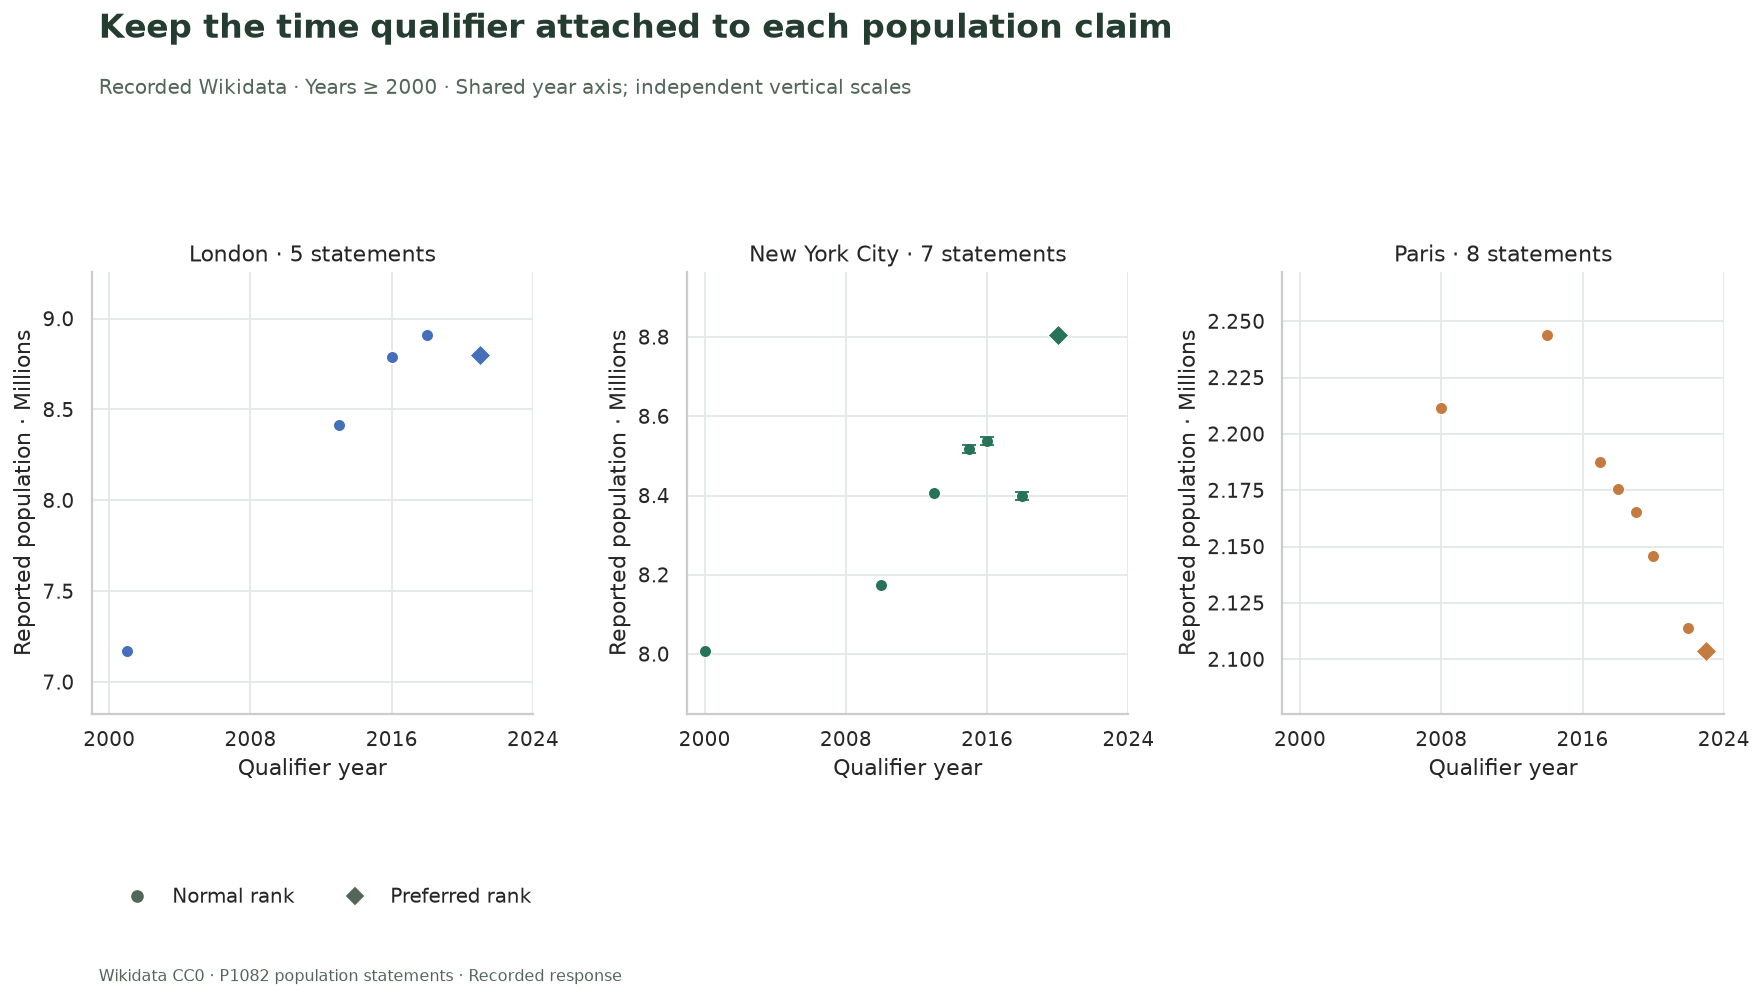

**20 statements meet the display criteria.** The diamond markers show preferred rank, not a claim that their dates equal today. Separate vertical scales support within-item inspection; cross-city size comparisons require harmonized boundaries and methods.

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 7.8), sharex=True)
cities = ["London", "New York City", "Paris"]
colors = {"London": "#456fba", "New York City": "#267358", "Paris": "#c57b40"}
for ax, city in zip(axes, cities, strict=True):
    rows = points[points.label == city]
    if rows.empty:
        ax.text(
            0.5, 0.5, "No eligible statements", ha="center", va="center", transform=ax.transAxes
        )
        ax.set_title(city)
        ax.set_xlabel("Qualifier year")
        continue
    for rank, marker in [("normal", "o"), ("preferred", "D")]:
        group = rows[rows["rank"] == rank]
        ax.scatter(
            group.statement_year,
            group.population_count / 1e6,
            color=colors[city],
            marker=marker,
            s=65 if rank == "preferred" else 45,
            edgecolors="white",
            linewidths=0.6,
            label=rank.title(),
        )
    bounded = rows[
        rows.lower_bound.notna()
        & rows.upper_bound.notna()
        & (rows.lower_bound <= rows.population_count)
        & (rows.upper_bound >= rows.population_count)
    ]
    if not bounded.empty:
        ax.errorbar(
            bounded.statement_year,
            bounded.population_count / 1e6,
            yerr=np.vstack(
                [
                    (bounded.population_count - bounded.lower_bound) / 1e6,
                    (bounded.upper_bound - bounded.population_count) / 1e6,
                ]
            ),
            fmt="none",
            color=colors[city],
            capsize=4,
        )
    ax.set_title(f"{city} · {len(rows)} statements")
    ax.set_xlabel("Qualifier year")
    ax.set_ylabel("Reported population · Millions")
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=4))
    ax.margins(x=0.12, y=0.20)
if not points.empty:
    for ax in axes:
        ax.set_xlim(points.statement_year.min() - 1, points.statement_year.max() + 1)
handles = [
    plt.Line2D([], [], marker="o", linestyle="", color="#52675a", label="Normal rank"),
    plt.Line2D([], [], marker="D", linestyle="", color="#52675a", label="Preferred rank"),
]
fig.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.08, 0.08), ncol=2, frameon=False)
finish(
    fig,
    "Keep the time qualifier attached to each population claim",
    f"{DATA_MODE.title()} Wikidata · Years ≥ {MIN_YEAR} · Shared year axis; independent vertical scales",
    "01_population_statements.png",
    bottom=0.20,
    source=source_line,
)
prose(
    f"**{len(points)} statements meet the display criteria.** The diamond markers show preferred rank, not a claim that their dates equal today. "
    "Separate vertical scales support within-item inspection; cross-city size comparisons require harmonized boundaries and methods."
)

## Measure row multiplication on the full source

Joining every qualifier to every reference snak forms combinations within each
statement. A COUNT over that expansion overstates the number of population claims,
and summing population there would repeat values. Compare it with the one-row-per-
statement table built above. This audit uses the entire retrieved history, so it
is intentionally unchanged by the display-year parameter.

In [9]:
%%sql
CREATE TABLE expanded AS SELECT s.requested_id,s.statement_id
FROM statements s
LEFT JOIN qualifiers q USING(source_api,entity_revision,requested_id,statement_id)
LEFT JOIN reference_snaks r USING(source_api,entity_revision,requested_id,statement_id);
CREATE TABLE join_counts AS SELECT e.label,
 (SELECT count(*) FROM statements s WHERE s.requested_id=e.requested_id) AS statement_rows,
 (SELECT count(*) FROM expanded x WHERE x.requested_id=e.requested_id) AS expanded_join_rows,
 (SELECT count(*) FROM population p WHERE p.requested_id=e.requested_id) AS aggregated_join_rows
FROM entities e;
SELECT * FROM join_counts ORDER BY label;

,label,statement_rows,expanded_join_rows,aggregated_join_rows
0,London,25,52,25
1,New York City,35,98,35
2,Paris,10,21,10


In [10]:
%%sql join_audit <<
SELECT * FROM join_counts ORDER BY label;

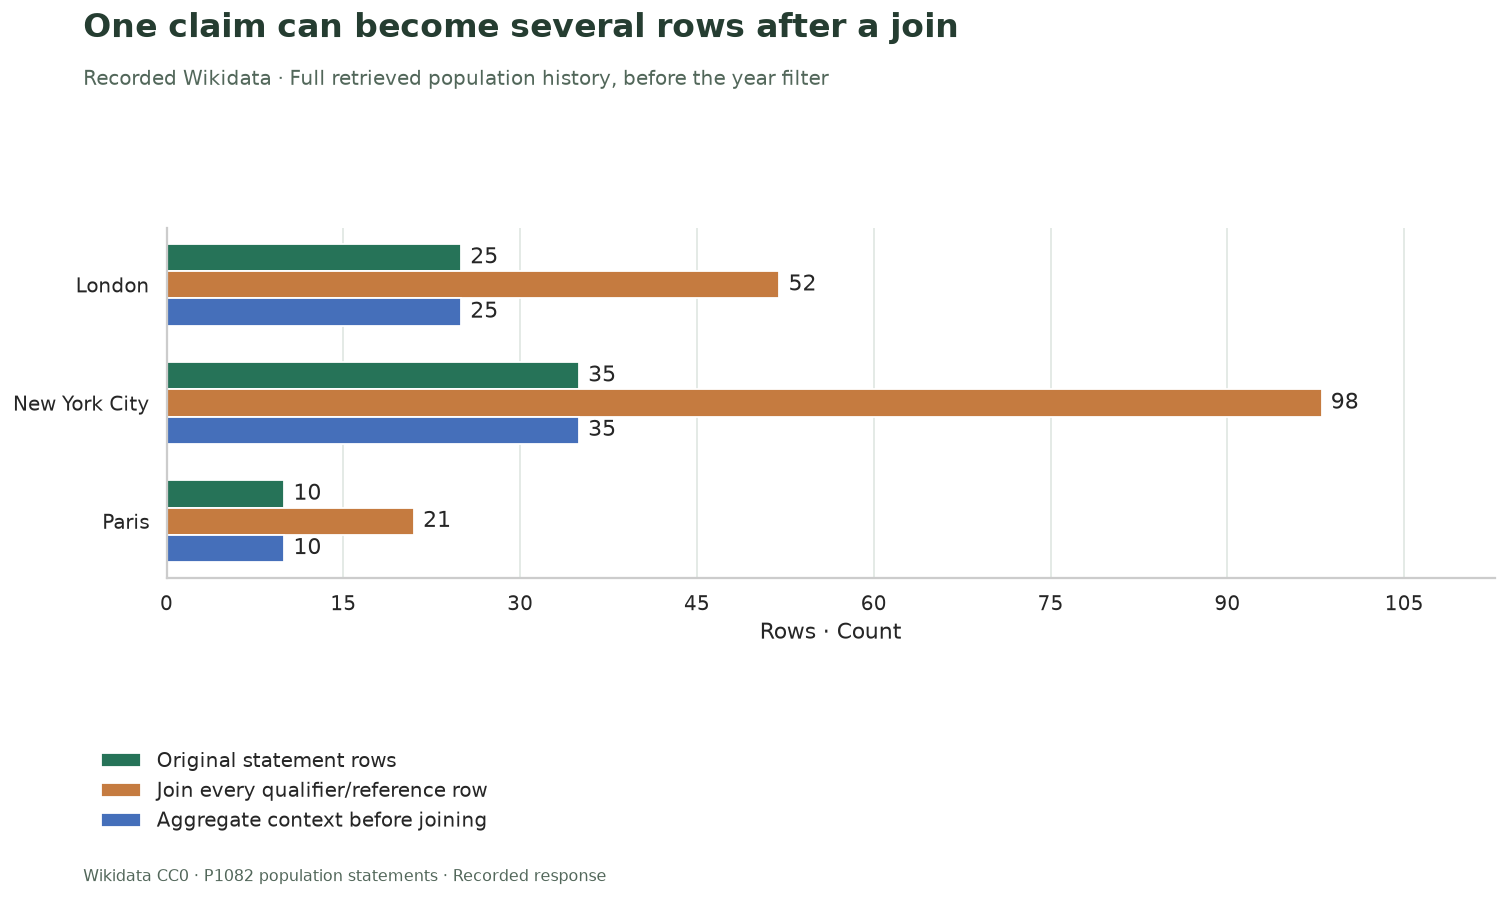

**70 statement rows become 171 expanded rows.** Aggregating the context first retains 70 rows. Keep the complete statement key when adding dates, references or other qualifier properties.

In [11]:
fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(join_audit))
width = 0.23
for offset, column, label, color in [
    (-width, "statement_rows", "Original statement rows", "#267358"),
    (0, "expanded_join_rows", "Join every qualifier/reference row", "#c57b40"),
    (width, "aggregated_join_rows", "Aggregate context before joining", "#456fba"),
]:
    bars = ax.barh(y + offset, join_audit[column], height=width, color=color, label=label)
    ax.bar_label(bars, padding=5)
ax.set_yticks(y, join_audit.label)
ax.invert_yaxis()
ax.set_xlabel("Rows · Count")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlim(0, join_audit.expanded_join_rows.max() * 1.15)
ax.grid(axis="y", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower left",
    bbox_to_anchor=(0.08, 0.06),
    ncol=1,
    frameon=False,
)
finish(
    fig,
    "One claim can become several rows after a join",
    f"{DATA_MODE.title()} Wikidata · Full retrieved population history, before the year filter",
    "02_join_multiplication.png",
    bottom=0.26,
    source=source_line,
)
prose(
    f"**{int(join_audit.statement_rows.sum())} statement rows become {int(join_audit.expanded_join_rows.sum())} expanded rows.** "
    f"Aggregating the context first retains {int(join_audit.aggregated_join_rows.sum())} rows. "
    "Keep the complete statement key when adding dates, references or other qualifier properties."
)

## Inspect preferred statements and validate the relationships

The worker's `best` selection is independent of the display-year filter. We join it
back on the complete context key and show its dates rather than calling it a current
population table. A reference group can contain multiple assertions about a source;
its count is a provenance diagnostic, not an evidence score.

In [12]:
%%sql
SELECT p.label,p.raw_amount,p.raw_time,p.time_precision,b.rank,p.reference_groups
FROM best b JOIN population p USING(source_api,entity_revision,requested_id,statement_id)
ORDER BY p.label,p.statement_id;

,label,raw_amount,raw_time,time_precision,rank,reference_groups
0,London,+8799728,+2021-00-00T00:00:00Z,9,preferred,1
1,New York City,+8804190,+2020-04-01T00:00:00Z,11,preferred,1
2,Paris,+2103778,+2023-01-01T00:00:00Z,11,preferred,1


In [13]:
%%sql checks <<
SELECT 'Three requested entities are present' AS check_name,count(*)=3 AND bool_and(NOT missing) AS passed FROM entities
UNION ALL SELECT 'Statement keys are unique',count(*)=count(DISTINCT (source_api,entity_revision,requested_id,statement_id)) FROM statements
UNION ALL SELECT 'Population join preserves statement count',(SELECT count(*) FROM population)=(SELECT count(*) FROM statements)
UNION ALL SELECT 'Population keys remain unique',count(*)=count(DISTINCT (source_api,entity_revision,requested_id,statement_id)) FROM population
UNION ALL SELECT 'All qualifiers match source statements',count(*)=0 FROM qualifiers q ANTI JOIN statements s USING(source_api,entity_revision,requested_id,statement_id)
UNION ALL SELECT 'All reference rows match source statements',count(*)=0 FROM reference_snaks r ANTI JOIN statements s USING(source_api,entity_revision,requested_id,statement_id)
UNION ALL SELECT 'Reference groups do not exceed snaks',bool_and(reference_groups<=reference_snaks) FROM population
UNION ALL SELECT 'Best statements belong to full history',count(*)=0 FROM best b ANTI JOIN statements s USING(source_api,entity_revision,requested_id,statement_id)
UNION ALL SELECT 'Plot respects inclusive year and precision',coalesce(bool_and(statement_year >= {{ MIN_YEAR }} AND time_precision>=9 AND date_qualifiers=1),true) FROM selected
UNION ALL SELECT 'Plotted quantities are finite and positive',coalesce(bool_and(isfinite(population_count::DOUBLE) AND population_count>0),true) FROM selected
UNION ALL SELECT 'Expanded join cannot drop source rows',bool_and(expanded_join_rows>=statement_rows) FROM join_counts
UNION ALL SELECT 'Aggregated join count agrees for every item',bool_and(aggregated_join_rows=statement_rows) FROM join_counts;

In [14]:
display(checks)
assert len(checks) == 12 and checks.passed.fillna(False).all(), checks
assert int(join_audit.statement_rows.sum()) == int(join_audit.aggregated_join_rows.sum())
if replay:
    assert len(replay.requests) == 5 and not replay.rejected
prose(
    f"**All {len(checks)} relationship checks passed.** No claim is made that reference counts or preferred rank establish statistical comparability. "
    + provenance
)

,check_name,passed
0,Three requested entities are present,True
1,Statement keys are unique,True
2,Population join preserves statement count,True
3,Population keys remain unique,True
4,All qualifiers match source statements,True
5,All reference rows match source statements,True
6,Reference groups do not exceed snaks,True
7,Best statements belong to full history,True
8,Plot respects inclusive year and precision,True
9,Plotted quantities are finite and positive,True


**All 12 relationship checks passed.** No claim is made that reference counts or preferred rank establish statistical comparability. Recorded public Wikidata · Captured 2026-11-14T10:39:37 UTC

## Try one controlled change

Set **`MIN_YEAR = 2010`**, restart the kernel and run all. Predict which dated
statements disappear from the population table and first chart. The full-source
join audit and second chart should stay identical in recorded mode. A smaller
plotted cohort does not mean earlier claims were deleted from Wikidata.

Reset **`MIN_YEAR = 2000`**. To inspect current source content, separately try
**`DATA_MODE = 'live'`**; the underlying statements and revisions may change, so that
is a new retrieval, not the same controlled comparison. A failed live request
stops execution and never silently uses the recording.

In [15]:
con.close()
if replay:
    replay.close()
secret_directory.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Wikidata CC0](https://www.wikidata.org/wiki/Wikidata:Licensing)